### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*

In [169]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association
%matplotlib inline
pd.set_option('display.max_columns', None)

In [170]:
df=pd.read_csv("amz_uk_price_prediction_dataset.csv.zip", compression='zip')

In [171]:
crosstable=pd.crosstab(df['category'], df['isBestSeller'],normalize="index").sort_values(by=True, ascending=False)
prevalent=crosstable[crosstable[True] > crosstable[False]]
if prevalent.empty:
    print("No categories where best-sellers are more prevalent.")
else:
    print(f"The most prevalent categories where best-sellers are more common than non-best-sellers are:\n{prevalent.index.tolist()}")

No categories where best-sellers are more prevalent.


2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

In [172]:
#chi-squared test
_, chi2_pvalue, _, _  = chi2_contingency(crosstable)
if chi2_pvalue < 0.05:
    print(f"The chi-squared test indicates a significant association between category and best-seller status (p-value: {chi2_pvalue:.4f}).")
else:
    print(f"There is not enough evidence to conclude a significant association between category and best-seller status (p-value: {chi2_pvalue:.4f}).")

#cramer's V
cramers_v = association(pd.crosstab(df['category'], df['isBestSeller']), method="cramer")
if cramers_v < 0.1:
    print   (f"Cramer's V indicates a very weak association between category and best-seller status (Cramer's V: {cramers_v:.4f}).")
elif cramers_v < 0.2:
    print   (f"Cramer's V indicates a weak association between category and best-seller status (Cramer's V: {cramers_v:.4f}).")
elif cramers_v < 0.3:
    print   (f"Cramer's V indicates a moderate association between category and best-seller status (Cramer's V: {cramers_v:.4f}).")
elif cramers_v < 0.5:
    print   (f"Cramer's V indicates a strong association between category and best-seller status (Cramer's V: {cramers_v:.4f}).")
else:
    print   (f"Cramer's V indicates a very strong association between category and best-seller status (Cramer's V: {cramers_v:.4f}).")

There is not enough evidence to conclude a significant association between category and best-seller status (p-value: 1.0000).
Cramer's V indicates a weak association between category and best-seller status (Cramer's V: 0.1223).


3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

Text(0.5, 1.0, 'Proportion of Best-Sellers by Category')

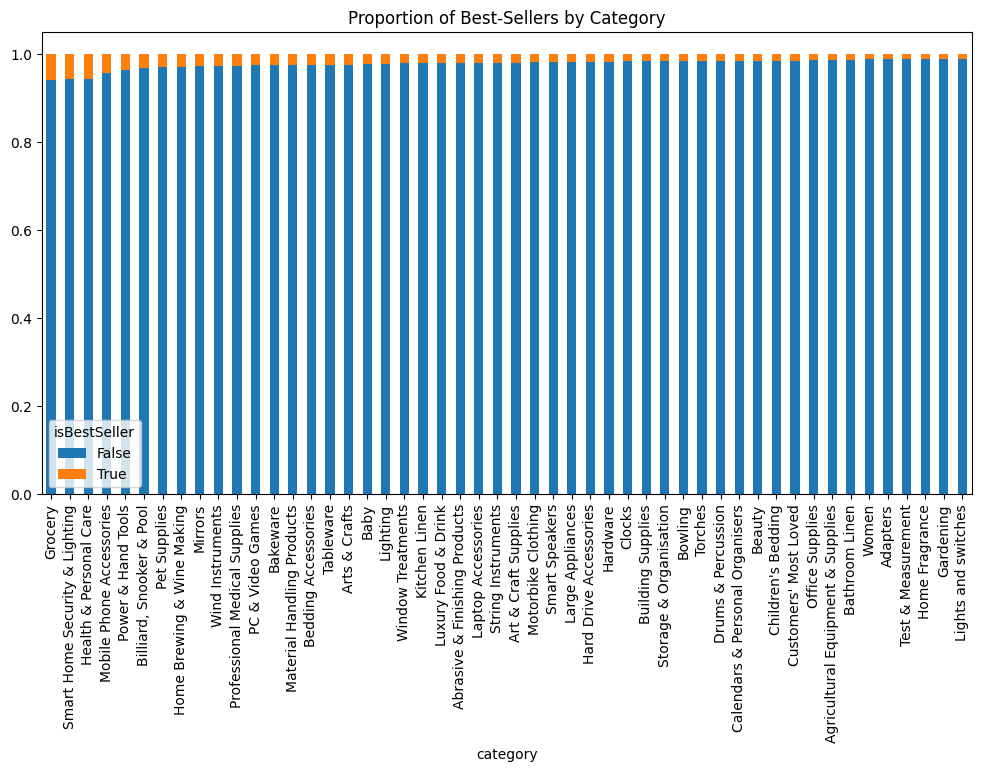

In [173]:
crosstable.head(50).plot(kind='bar', stacked=True, figsize=(12, 6))
plt.title('Proportion of Best-Sellers by Category')

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

In [174]:
def outlier_slayer(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify the outliers
    outliers = data[(data < lower_bound) | (data > upper_bound)]

    return outliers

outliers = outlier_slayer(df['price'])
df_no_outliers = df.drop(index=outliers.index)
df_no_outliers.sort_values(by='price', ascending=False).head(20)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
2232551,2579883,B0B8PD95K3,"Kodak PIXPRO FZ45 1/2.3"" Appareil-photo compac...",3.6,105,99.99,False,0,Digital Cameras
906996,987657,B0CBCP4HVG,Trespass Mens Hooded Activewear Outdoor Jacket...,0.0,0,99.99,False,0,Sports & Outdoors
2232748,2580080,B08D6QYBN3,AGFA PHOTO Realishot WP8000 Waterproof Digital...,5.0,1,99.99,False,0,Digital Cameras
2232682,2580014,B0BHT56TLX,"Sunscien Autofocus Digital Camera, 4K 48MP Vlo...",4.4,408,99.99,False,0,Digital Cameras
2232504,2579834,B0B8PD8TTP,"Kodak PIXPRO FZ45 1/2.3"" Appareil-photo compac...",4.0,131,99.99,False,0,Digital Cameras
2232722,2580054,B07NWY7K88,KODAK Smile Instant Print Digital Camera – Sli...,4.3,2545,99.99,False,0,Digital Cameras
2232616,2579948,B07NWXJKDX,KODAK Smile Instant Print Digital Camera – Sli...,4.3,2545,99.99,False,0,Digital Cameras
2232769,2580101,B07NWYXQ5P,KODAK Smile Instant Print Digital Camera – Sli...,4.3,2545,99.99,False,0,Digital Cameras
1164909,1286814,B0BR3HJ7S2,"KOSPET Smart Watch for Men(Answer/Make Calls),...",3.9,1270,99.99,False,0,Smartwatches
126950,137414,B0B3SFC447,Fox Racing Men's Flexair Ascent Shorts,0.0,0,99.99,False,0,Sports & Outdoors


1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

C:\Users\laura\AppData\Local\Temp\ipykernel_27528\2601807491.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x="category", y="price", data=df_top20,palette="coolwarm")


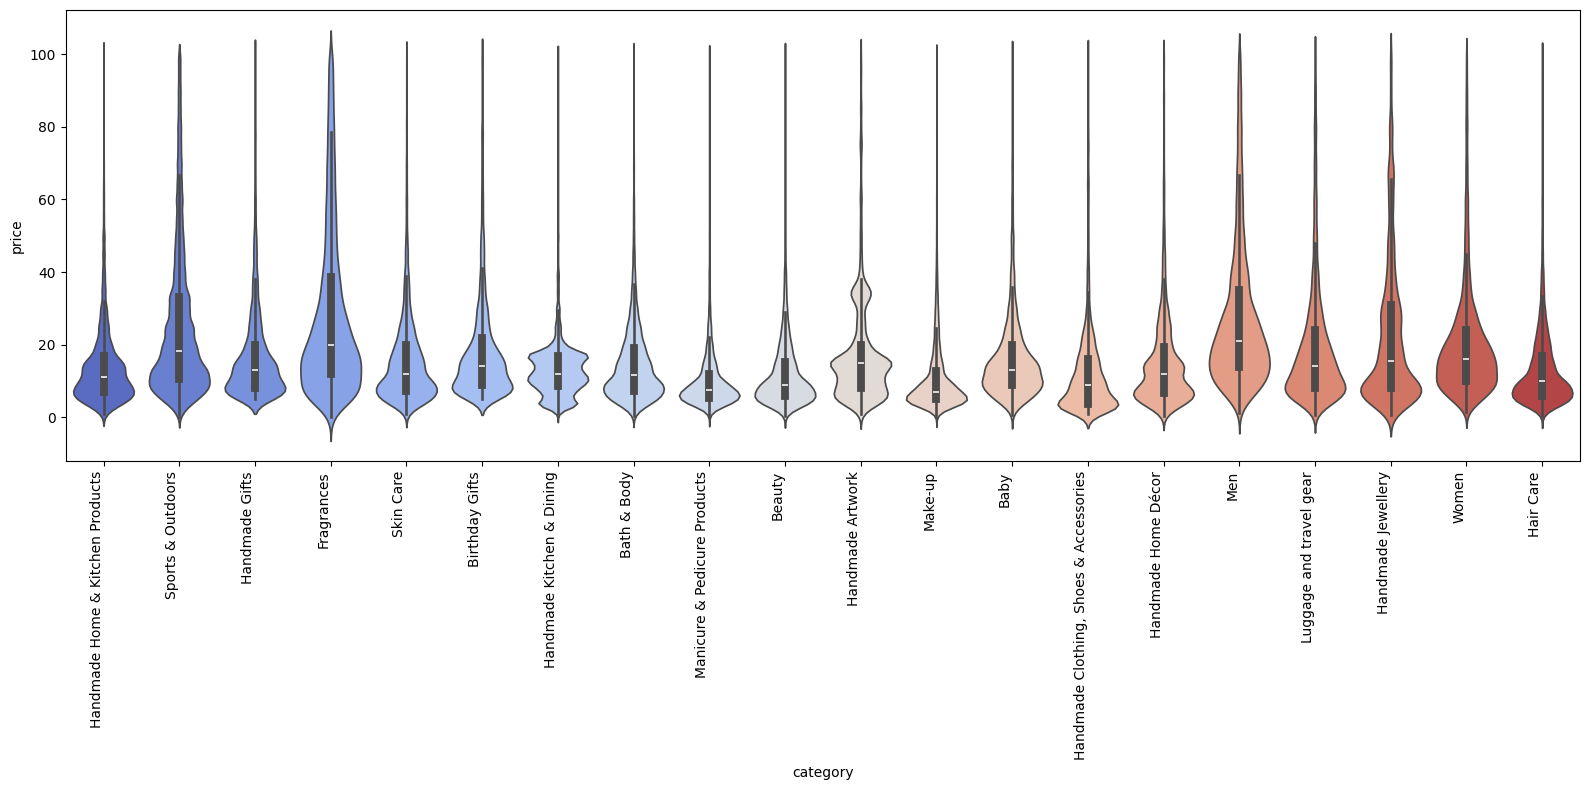

In [175]:
top20_categories = df_no_outliers['category'].value_counts().nlargest(20).index
df_top20 = df_no_outliers[df_no_outliers['category'].isin(top20_categories)]
plt.figure(figsize=(16, 8))
sns.violinplot(x="category", y="price", data=df_top20,palette="coolwarm")
plt.xticks(rotation=90, ha='right')
plt.tight_layout()
plt.show()

In [176]:
median_by_category = df_no_outliers.groupby('category')['price'].median().sort_values(ascending=False)
print(f"The product category that tends to have the highest median price is {median_by_category.index[0]} with a median price of {median_by_category.iloc[0]:.2f} Pounds.")

The product category that tends to have the highest median price is Desktop PCs with a median price of 74.00 Pounds.


2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

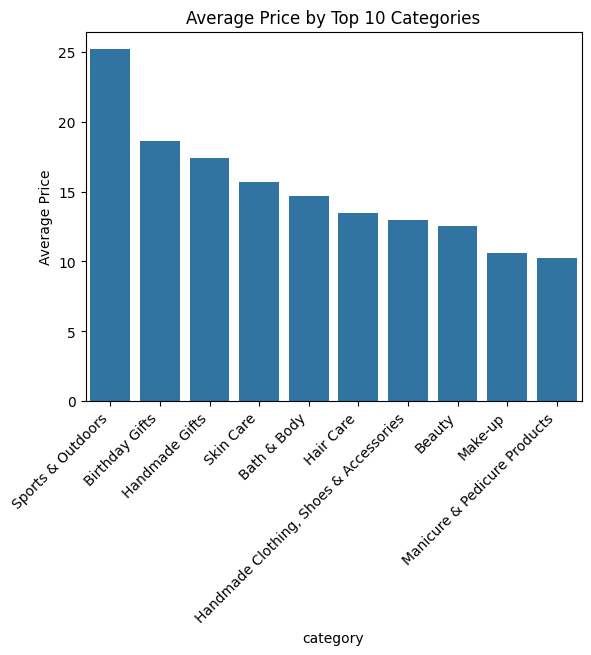

In [177]:
top10_cat=df_no_outliers['category'].value_counts().head(10).index
avg_price = df_no_outliers[df_no_outliers['category'].isin(top10_cat)].groupby('category')['price'].mean().sort_values(ascending=False)
sns.barplot(x=avg_price.index, y=avg_price.values)
plt.xticks(rotation=45, ha='right')
plt.title('Average Price by Top 10 Categories')
plt.ylabel('Average Price')
plt.show()

In [178]:
avg_price= df_no_outliers.groupby("category")["price"].mean().sort_values(ascending=False)
print(f"The category with the highest average price is {avg_price.index[0]} with an average price of {avg_price.iloc[0]:.2f} Pounds.")


The category with the highest average price is Motherboards with an average price of 68.77 Pounds.


3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

Text(0.5, 1.0, 'Distribution of Ratings by Top 10 Categories')

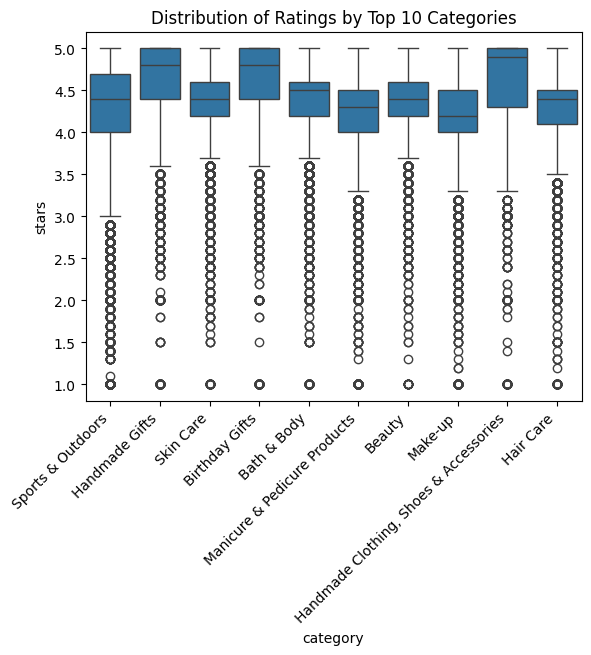

In [179]:
new_df=df_no_outliers.copy()
new_df.loc[new_df['reviews'] == 0, 'stars'] = np.nan

sns.boxplot(x="category", y="stars", data=new_df[new_df['category'].isin(top10_cat)])
plt.xticks(rotation=45, ha='right')
plt.title('Distribution of Ratings by Top 10 Categories')

In [180]:
median_ratings = new_df.groupby('category')['stars'].median().sort_values(ascending=False)
print(f"The category with the highest median rating is {median_ratings.index[0]} with a median rating of {median_ratings.iloc[0]:.2f} stars.")

The category with the highest median rating is Handmade Artwork with a median rating of 5.00 stars.


### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?

In [181]:
correlation_coef=new_df['price'].corr(new_df['stars'])

if abs(correlation_coef) < 0.1:
    print(f"The correlation between price and stars is very weak (correlation coefficient: {correlation_coef:.4f}).")
elif abs(correlation_coef) < 0.3:
    print(f"The correlation between price and stars is weak (correlation coefficient: {correlation_coef:.4f}).")
elif abs(correlation_coef) < 0.5:
    print(f"The correlation between price and stars is moderate (correlation coefficient: {correlation_coef:.4f}).")
else:
    print(f"The correlation between price and stars is strong (correlation coefficient: {correlation_coef:.4f}).")

The correlation between price and stars is very weak (correlation coefficient: 0.0067).


2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

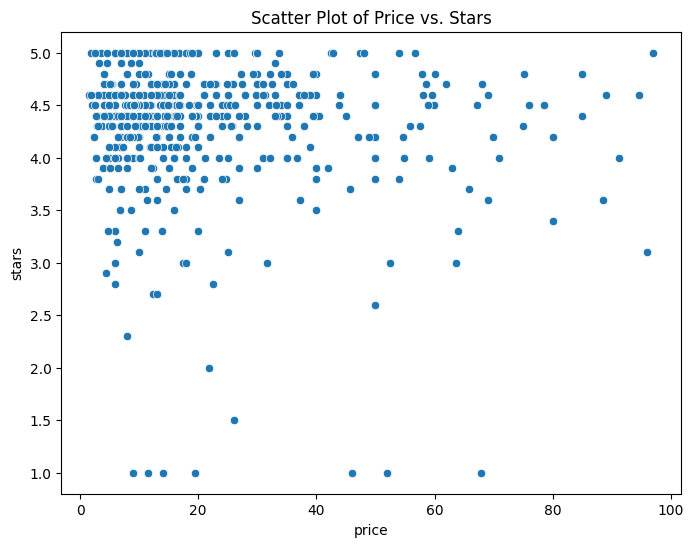

The scatter plot shows the relationship between price and star ratings, with a sample of 1000 products for clarity.
The pattern suggests that for lower-priced products, there is a wider range of star ratings, while higher-priced products tend to have more consistent star ratings, often clustered around higher values. This could indicate that while price may not be a strong predictor of star ratings, there is a tendency for higher-priced products to receive better ratings, possibly due to perceived quality or customer expectations.


In [182]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x='price', y='stars', data=new_df.sample(1000, random_state=42))  # Sample 1000 points for better visualization
plt.title('Scatter Plot of Price vs. Stars')
plt.show()
print("The scatter plot shows the relationship between price and star ratings, with a sample of 1000 products for clarity.")
print("The pattern suggests that for lower-priced products, there is a wider range of star ratings, while higher-priced products tend to have more consistent star ratings, often clustered around higher values. This could indicate that while price may not be a strong predictor of star ratings, there is a tendency for higher-priced products to receive better ratings, possibly due to perceived quality or customer expectations.")

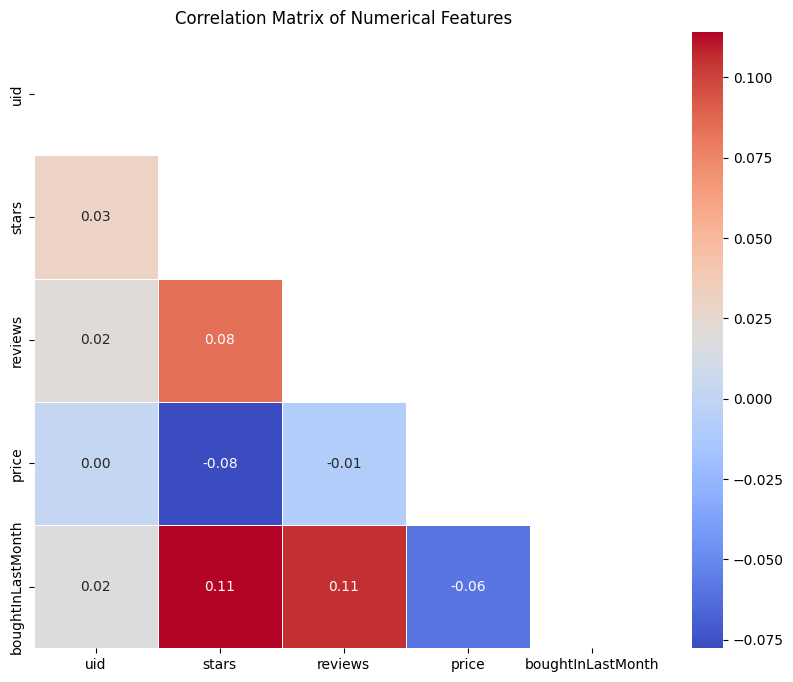

In [183]:
numerical_cols = df_no_outliers.select_dtypes(include=[np.number]).columns
corr_matrix = df_no_outliers[numerical_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, mask=mask, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix of Numerical Features')
plt.show()

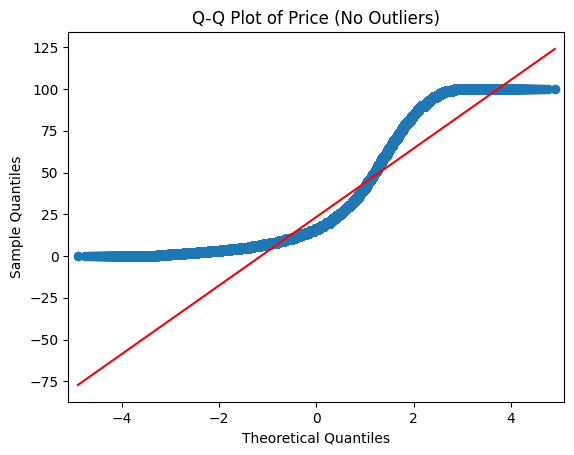

In [184]:
import statsmodels.api as sm
sm.qqplot(df_no_outliers["price"],line='s')
plt.title('Q-Q Plot of Price (No Outliers)')
plt.show()

In [185]:
print(
"""The distribution of price is:
Right-skewed (the S-shape and flat tails are classic signs)
Bounded between ~0 and ~100 due to outlier removal
Highly concentrated in the lower-to-mid price range""")

The distribution of price is:
Right-skewed (the S-shape and flat tails are classic signs)
Bounded between ~0 and ~100 due to outlier removal
Highly concentrated in the lower-to-mid price range


**Bonus**: 

- Do the same analysis without taking out the outliers. What are your insights?

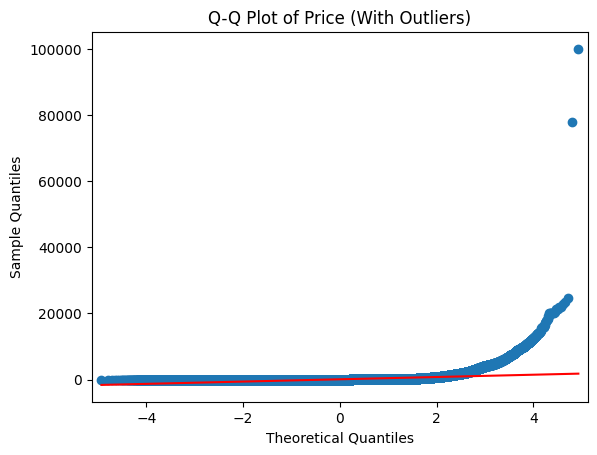

In [186]:
sm.qqplot(df["price"],line='s')
plt.title('Q-Q Plot of Price (With Outliers)')
plt.show()

In [187]:
print("Because the y-axis in the Q-Q plot with outliers is stretched due to extreme values, it is difficult to assess the normality of the distribution. The presence of outliers can distort the overall shape of the distribution, making it appear more skewed and less normal than it actually is.")

Because the y-axis in the Q-Q plot with outliers is stretched due to extreme values, it is difficult to assess the normality of the distribution. The presence of outliers can distort the overall shape of the distribution, making it appear more skewed and less normal than it actually is.
